# Predicting Water Turbidity (TSS) from Landsat Imagery — Five-Model Comparison

**2107541 Machine Learning for Environmental Applications** · Project 2: Environmental Machine Learning Project
Chulalongkorn University, Faculty of Engineering · AY2026 Semester 1

**Contributor:** Chatrphol Ovanonchai (6730084521)

> This notebook is the **five-model version** of the project (branch `5-Model-Assignment`).
> It reuses the problem, dataset, cleaning rules and spectral features from the ensemble-learning version on the `main` branch,
> and follows the nine steps of the Project 2 assignment brief.

## Overview

| Assignment step | Section in this notebook |
|---|---|
| 1. Find an environmental dataset | [1. Environmental dataset](#1.-Environmental-Dataset) — AquaSat (Ross et al., 2019) |
| 2. Define the problem | [2. Problem definition](#2.-Problem-Definition) — regression of TSS, research questions |
| 3. Data preparation / preprocessing | [3. Data preparation](#3.-Data-Preparation-/-Preprocessing) — 4 quality filters, EDA |
| 4. Feature engineering | [4. Feature engineering](#4.-Feature-Engineering) — 21 features (spectral indices, season, site context) |
| 5. Build multiple ML models (≥ 5) | [5. Build five models](#5.-Build-Five-Machine-Learning-Models) — Linear, Polynomial Ridge, KNN, Decision Tree, SVR |
| 6. Hyperparameter tuning | [6. Hyperparameter tuning](#6.-Hyperparameter-Tuning) — `GridSearchCV` + `GroupKFold` |
| 7. Model evaluation | [7. Model evaluation](#7.-Model-Evaluation-on-Unseen-Sites) — test set of unseen sites, used once |
| 8. Feature importance (explainable ML) | [8. Feature importance](#8.-Feature-Importance-(Explainable-ML)) — permutation importance, SHAP, tree, coefficients |
| 9. Environmental interpretation | [9. Environmental interpretation](#9.-Environmental-Interpretation) |

**The five models** (all covered in the course lectures):

1. **Multiple Linear Regression** — baseline (Lecture 5)
2. **Polynomial Ridge Regression** — polynomial feature expansion + L2 regularization (Lecture 6)
3. **K-Nearest Neighbors Regression** — instance-based (Lecture 4)
4. **Decision Tree Regression** — rule-based (Lecture 2)
5. **Support Vector Regression (RBF kernel)** — kernel method (Lecture 3)

**Key rule — no data leakage between sites.** The same water site is sampled many times. A random row split would let a model
memorise a site and then be "tested" on that same site. Every split in this notebook is therefore grouped by `SiteID`,
so all scores describe performance on **sites the model has never seen**.

Figures are saved to [`../figures/`](../figures/).

## 0. Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import seaborn as sns
import sklearn
import shap

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.svm import SVR
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             confusion_matrix, accuracy_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_JOBS = -1          # use all CPU cores for cross-validation and grid search

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | shap {shap.__version__}")

numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2 | shap 0.54.1


In [2]:
## paths: works when the notebook is started from the repo root or from notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = REPO_ROOT / "data" / "aquasat.csv.gz"
DATA_URL = ("https://raw.githubusercontent.com/NuBFightForMyDream/"
            "2107541_MLEnvi_Project_PredictingWaterTurbidityWithTSS/5-Model-Assignment/data/aquasat.csv.gz")
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

## plotting style: one fixed colour per model (same colour in every figure)
MODEL_NAMES = ["Linear Regression", "Polynomial Ridge", "KNN", "Decision Tree", "SVR"]
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
GRAY, INK, INK_2 = "#a3a29c", "#0b0b0b", "#52514e"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5cf", "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
})


def save_fig(fig, name):
    """Save a figure to figures/<name>.png and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()

## 1. Environmental Dataset

**AquaSat** ([Ross et al., 2019, *Water Resources Research*](https://doi.org/10.1029/2019WR024883), CC BY 4.0,
[Figshare](https://figshare.com/articles/dataset/AquaSat/8139383)) pairs **in-situ water quality samples** from the US Water
Quality Portal and LAGOS-NE with **Landsat 5, 7 and 8 surface reflectance** taken over the same location within about ±1 day.
Each row is one *matchup*: one water sample + one satellite pixel window.

The raw file `sr_wq_rs_join.csv` (291 MB) is above GitHub's 100 MB limit, so the repo stores a gzip copy
`data/aquasat.csv.gz` (74 MB). pandas reads `.gz` directly. If the local file is missing (for example on Google Colab),
the notebook downloads it from this repository instead.

Columns used in this project (full dictionary: [`data/aquasat_column_dictionary.pdf`](../data/aquasat_column_dictionary.pdf)):

| Column | Meaning |
|---|---|
| `SiteID` | Sampling site identifier (used to group the splits) |
| `date` | Sampling date |
| `sat` | Landsat mission (5, 7 or 8) |
| `blue`, `green`, `red`, `nir`, `swir1`, `swir2` | Median surface reflectance of water pixels × 10⁴ |
| `qa` | Landsat pixel quality code (68 / 324 = clear water) |
| `pwater` | % of the pixel window classified as water |
| `type` | Site type: Stream, Estuary, Lake or Facility |
| `lat`, `long` | Site coordinates |
| `tss` | **Total Suspended Solids (mg/L)** — the target |

In [3]:
t0 = time.time()
if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
    source = DATA_PATH.relative_to(REPO_ROOT)
else:
    df_raw = pd.read_csv(DATA_URL)
    source = DATA_URL
print(f"Loaded {len(df_raw):,} rows x {df_raw.shape[1]} columns from {source} ({time.time() - t0:.0f} s)")

Loaded 603,432 rows x 43 columns from data/aquasat.csv.gz (5 s)


In [4]:
USED_COLS = ["SiteID", "date", "sat", "blue", "green", "red", "nir", "swir1", "swir2",
             "qa", "pwater", "type", "lat", "long", "tss"]
df_raw[USED_COLS].head()

,SiteID,date,sat,blue,green,red,nir,swir1,swir2,qa,pwater,type,lat,long,tss
0,8348,2004-08-23,7,230.0,243.0,215.0,383.000000,228.0,172.0,68.0,97.0,Lake,45.508496,-67.829399,NaN
1,8348,2001-08-23,5,200.0,212.0,130.0,242.000000,28.0,16.0,68.0,97.0,Lake,45.508496,-67.829399,NaN
2,8348,2003-06-26,5,543.0,495.0,392.0,639.000000,248.0,186.0,66.0,97.0,Lake,45.508496,-67.829399,NaN
3,7889,1988-07-18,5,269.0,270.0,220.0,364.470719,149.0,86.0,68.0,95.0,Lake,45.618910,-67.585147,NaN
4,7889,1990-07-08,5,146.0,137.0,97.0,212.000000,63.0,21.0,68.0,95.0,Lake,45.618910,-67.585147,NaN


In [5]:
## AquaSat stores several water quality parameters, but most rows only have some of them
WQ_PARAMS = ["tss", "secchi", "chl_a", "doc", "tis", "p_sand"]
pd.DataFrame({
    "rows with a value": df_raw[WQ_PARAMS].notna().sum(),
    "missing (%)": (df_raw[WQ_PARAMS].isna().mean() * 100).round(1),
})

,rows with a value,missing (%)
tss,159819,73.5
secchi,489443,18.9
chl_a,220192,63.5
doc,42418,93.0
tis,12664,97.9
p_sand,683,99.9


Only about a quarter of the matchups have a TSS measurement, which is why the cleaning step keeps rows with a valid TSS value only.
The other parameters (`chl_a`, `doc`, `secchi`, `tis`, `p_sand`) are different targets and are dropped.

## 2. Problem Definition

**Environmental problem.** Turbidity — measured here as **Total Suspended Solids (TSS)** — is one of the most important indicators
of surface water quality. High TSS comes from soil erosion, agricultural and urban runoff, construction, dredging and the
resuspension of bottom sediment. It blocks light for aquatic plants, clogs fish gills, carries attached nutrients, metals and
pathogens, and raises the cost of drinking water treatment. Field sampling is accurate but expensive, so most rivers, lakes and
estuaries are sampled only a few times, if ever.

**Why machine learning?** Landsat observes almost every water body on Earth every 8–16 days and the archive goes back to 1984.
Suspended particles change the colour of water (they scatter more red and near-infrared light), but the relationship between
reflectance and TSS is non-linear and depends on particle type, water depth, sensor and atmosphere. Instead of a hand-made
physical model, supervised ML can **learn the mapping from ~128 k paired field/satellite samples** and then estimate TSS wherever
there is a clear Landsat pixel.

**ML task.** Supervised **regression**.

- **Input (X):** 21 features from Landsat surface reflectance (6 bands, 7 indices/ratios, brightness), season and site context.
- **Target (y):** `log(1 + TSS)`. TSS is strongly right-skewed (median ≈ 11 mg/L, maximum > 70,000 mg/L), so the log scale stops a few extreme samples from dominating the loss.
- **Unit of generalisation:** the *site*. Train and test sets never share a `SiteID`.

**Research questions**

- **RQ1.** Can Landsat surface reflectance predict TSS at water sites that were *never* used for training, and how accurate is that prediction?
- **RQ2.** Which of five basic supervised learning models performs best, and how much do non-linearity and hyperparameter tuning help over a linear baseline?
- **RQ3.** Does adding simple site context (water-body type, Landsat sensor) to the spectral features improve the prediction?
- **RQ4.** Which features drive the predictions, and are they consistent with the optics of suspended sediment?
- **RQ5.** Where does the model fail (by TSS level and water-body type), and what does that mean for water quality monitoring?

**Evaluation metrics** (all on the log scale unless stated): R², RMSE, MAE; plus two metrics that are easier to explain
in environmental terms: the share of predictions **within a factor of 2** of the measured TSS, and the accuracy of
**turbidity classes** (low / moderate / high).

## 3. Data Preparation / Preprocessing

### 3.1 Cleaning

The same four quality filters as the `main` branch:

1. **Valid TSS** — keep rows with a measured TSS > 0 mg/L.
2. **Valid surface reflectance** — every band in (0, 10000]; values outside this range are sensor or atmospheric-correction errors.
3. **Clear-water pixels** — Landsat pixel QA code 68 (Landsat 5/7) or 324 (Landsat 8). Removes cloud, shadow, ice and land.
4. **Mostly water** — `pwater` ≥ 50 % so that the pixel window is not contaminated by the shoreline or river bank.

In [6]:
BANDS = ["blue", "green", "red", "nir", "swir1", "swir2"]
UNUSED = ["chl_a", "doc", "secchi", "tis", "p_sand"]
clean_log = []


def keep_rows(data, condition, step):
    """Keep rows where condition is True and record how many rows were removed."""
    out = data[condition]
    clean_log.append({"step": step, "rows before": len(data), "rows after": len(out),
                      "removed": len(data) - len(out)})
    return out


df = df_raw.drop(columns=UNUSED)
df = keep_rows(df, df["tss"].notna() & (df["tss"] > 0), "1. Valid TSS (> 0 mg/L)")
df = keep_rows(df, ((df[BANDS] > 0) & (df[BANDS] <= 10000)).all(axis=1), "2. Valid reflectance (0, 10000]")
df = keep_rows(df, df["qa"].round().isin([68, 324]), "3. Clear-water pixel (QA 68 / 324)")
df = keep_rows(df, df["pwater"] >= 50, "4. Mostly water (pwater >= 50 %)")
df = df.reset_index(drop=True).copy()

pd.DataFrame(clean_log).set_index("step")

,rows before,rows after,removed
step,,,
1. Valid TSS (> 0 mg/L),603432,159819,443613
"2. Valid reflectance (0, 10000]",159819,157420,2399
3. Clear-water pixel (QA 68 / 324),157420,135893,21527
4. Mostly water (pwater >= 50 %),135893,128603,7290


In [7]:
years = pd.to_datetime(df["date"]).dt.year
print(f"Clean dataset: {len(df):,} matchups | {df['SiteID'].nunique():,} sites | {years.min()}–{years.max()}")
print("Landsat mission:", df["sat"].value_counts().sort_index().to_dict())

site_summary = (df.groupby("type")
                  .agg(matchups=("tss", "size"), sites=("SiteID", "nunique"),
                       median_TSS=("tss", "median"), p90_TSS=("tss", lambda s: s.quantile(0.9)))
                  .sort_values("matchups", ascending=False))
site_summary["share (%)"] = (site_summary["matchups"] / len(df) * 100).round(1)
site_summary.round(1)

Clean dataset: 128,603 matchups | 21,129 sites | 1984–2019
Landsat mission: {5: 57974, 7: 56998, 8: 13631}


,matchups,sites,median_TSS,p90_TSS,share (%)
type,,,,,
Stream,62683,6064,13.0,94.0,48.7
Estuary,34664,7717,13.0,41.3,27.0
Lake,30201,7125,7.0,29.7,23.5
Facility,1055,223,7.0,90.6,0.8


> **Note.** The data are not only lakes: about half of the matchups are **streams/rivers**, a quarter are **estuaries**,
> and a quarter are **lakes** (plus a few "facility" sites). Each site has exactly one type. Streams and estuaries
> are clearly more turbid (median ≈ 13 mg/L) than lakes (≈ 7 mg/L), which motivates the context features in Section 4.

### 3.2 Exploratory data analysis

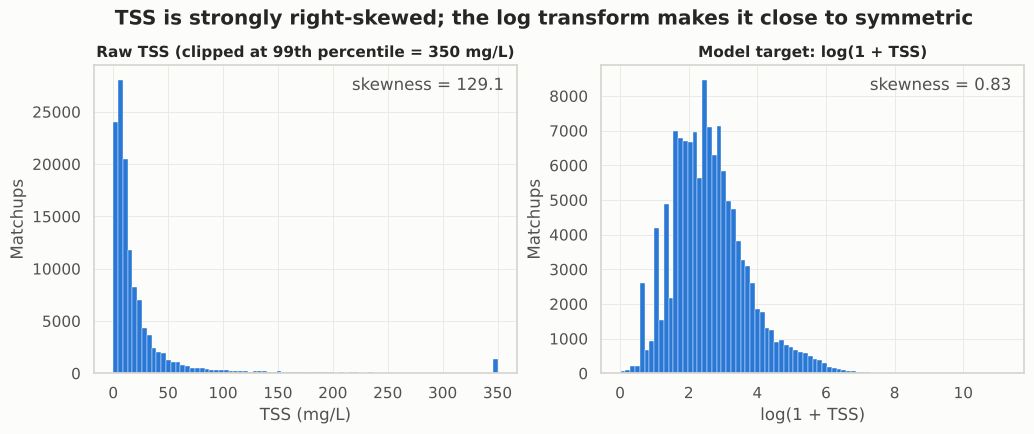

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

p99 = df["tss"].quantile(0.99)
axes[0].hist(df["tss"].clip(upper=p99), bins=80, color=MODEL_COLORS["Linear Regression"], edgecolor="#fcfcfb", linewidth=0.3)
axes[0].set(title=f"Raw TSS (clipped at 99th percentile = {p99:.0f} mg/L)", xlabel="TSS (mg/L)", ylabel="Matchups")
axes[0].text(0.97, 0.92, f"skewness = {df['tss'].skew():.1f}", transform=axes[0].transAxes, ha="right", color=INK_2)

axes[1].hist(np.log1p(df["tss"]), bins=80, color=MODEL_COLORS["Linear Regression"], edgecolor="#fcfcfb", linewidth=0.3)
axes[1].set(title="Model target: log(1 + TSS)", xlabel="log(1 + TSS)", ylabel="Matchups")
axes[1].text(0.97, 0.92, f"skewness = {np.log1p(df['tss']).skew():.2f}", transform=axes[1].transAxes, ha="right", color=INK_2)

fig.suptitle("TSS is strongly right-skewed; the log transform makes it close to symmetric", fontweight="bold", y=1.02)
save_fig(fig, "01_tss_distribution")

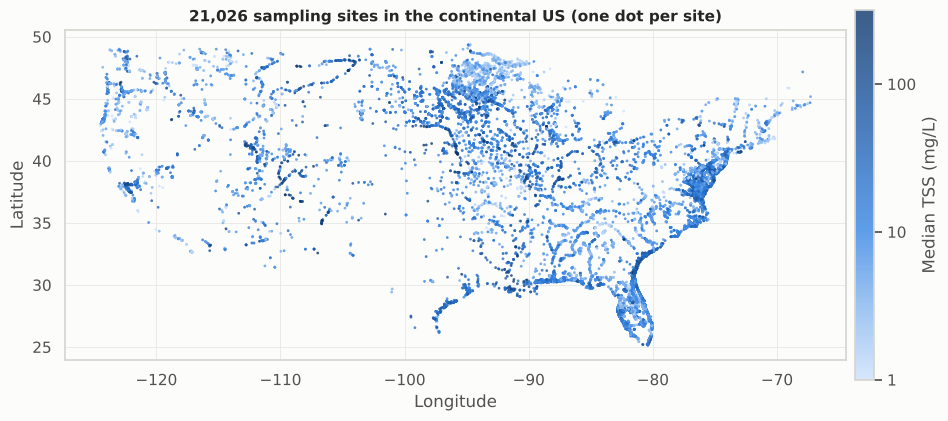

In [9]:
## one point per site, coloured by the site's median TSS
sites = (df.groupby("SiteID")
           .agg(lat=("lat", "first"), long=("long", "first"), median_tss=("tss", "median"), n=("tss", "size"))
           .query("-130 < long < -60 and 23 < lat < 52"))   # continental US for display

fig, ax = plt.subplots(figsize=(12, 6))
sc = ax.scatter(sites["long"], sites["lat"], c=np.log10(sites["median_tss"]), cmap=BLUES,
                s=4, alpha=0.8, linewidths=0, vmin=0, vmax=2.5)
cbar = fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.01)
cbar.set_label("Median TSS (mg/L)")
cbar.set_ticks([0, 1, 2])
cbar.set_ticklabels(["1", "10", "100"])
ax.set(title=f"{len(sites):,} sampling sites in the continental US (one dot per site)",
       xlabel="Longitude", ylabel="Latitude", aspect="equal")
save_fig(fig, "02_site_map")

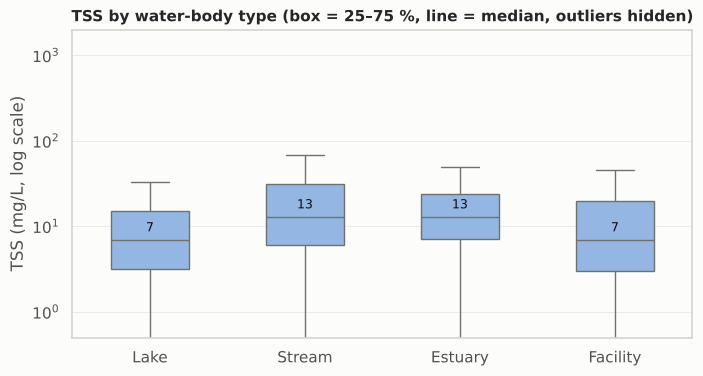

In [10]:
order = ["Lake", "Stream", "Estuary", "Facility"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="type", y="tss", order=order, color="#86b6ef", fliersize=0, width=0.5,
            linewidth=1, ax=ax)
ax.set_yscale("log")
ax.set_ylim(0.5, 2000)
for i, t in enumerate(order):
    med = df.loc[df["type"] == t, "tss"].median()
    ax.text(i, med * 1.15, f"{med:.0f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set(title="TSS by water-body type (box = 25–75 %, line = median, outliers hidden)",
       xlabel="", ylabel="TSS (mg/L, log scale)")
save_fig(fig, "03_tss_by_water_type")

## 4. Feature Engineering

### 4.1 Spectral features (same design as the `main` branch)

| Feature | Formula | Why it matters for TSS |
|---|---|---|
| `blue` … `swir2` | surface reflectance × 10⁻⁴ | Raw signal; particles scatter light, so turbid water is brighter |
| `NDTI` | (R − G) / (R + G) | Normalized Difference Turbidity Index; sediment shifts the water colour from green to red |
| `NDWI` | (G − NIR) / (G + NIR) | Water index; drops when NIR rises because of very high sediment |
| `NDSSI` | (B − NIR) / (B + NIR) | Normalized Difference Suspended Sediment Index |
| `R_G`, `R_B`, `G_B`, `NIR_R` | band ratios | Ratios cancel part of the illumination / atmosphere effect that affects all bands |
| `log_visible` | log(B + G + R) | Overall brightness of the water |
| `doy_sin`, `doy_cos` | sin / cos(2π · day-of-year / 365) | Season (spring runoff, summer algae) without a jump between 31 Dec and 1 Jan |

### 4.2 Site-context features (new in this version)

The `main` branch listed *"include sensor type (Landsat 5/7/8)"* as room for improvement. Section 3 also showed that
TSS depends strongly on the type of water body. Both are known for any location without field sampling, so they are
safe to use at prediction time:

| Feature | Encoding |
|---|---|
| `type_Stream`, `type_Estuary`, `type_Facility` | one-hot water-body type (reference category = Lake) |
| `landsat_7`, `landsat_8` | one-hot Landsat mission (reference = Landsat 5); bands differ slightly between sensors |

One category of each variable is dropped so the linear models have no perfectly collinear columns.

In [11]:
## target
df["tss_log"] = np.log1p(df["tss"])

## surface reflectance: stored x 10^4 -> convert to reflectance (0–1)
df[BANDS] = df[BANDS] * 1e-4
b, g, r, n = (df[c] for c in ["blue", "green", "red", "nir"])

## normalized difference indices and band ratios
df["NDTI"] = (r - g) / (r + g)
df["NDWI"] = (g - n) / (g + n)
df["NDSSI"] = (b - n) / (b + n)
df["R_G"], df["R_B"], df["G_B"], df["NIR_R"] = r / g, r / b, g / b, n / r
df["log_visible"] = np.log(b + g + r)

## season (cyclical encoding of day of year)
doy = pd.to_datetime(df["date"]).dt.day_of_year
df["doy_sin"] = np.sin(2 * np.pi * doy / 365)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365)

## site context: one-hot encoding with a reference category dropped
for t in ["Stream", "Estuary", "Facility"]:          # reference = Lake
    df[f"type_{t}"] = (df["type"] == t).astype(float)
for s in [7, 8]:                                     # reference = Landsat 5
    df[f"landsat_{s}"] = (df["sat"] == s).astype(float)

SPECTRAL_FEATURES = BANDS + ["NDTI", "NDWI", "NDSSI", "R_G", "R_B", "G_B", "NIR_R",
                             "log_visible", "doy_sin", "doy_cos"]
CONTEXT_FEATURES = ["type_Stream", "type_Estuary", "type_Facility", "landsat_7", "landsat_8"]
FEATURES = SPECTRAL_FEATURES + CONTEXT_FEATURES

X = df[FEATURES]
y = df["tss_log"]
groups = df["SiteID"]

print(f"X: {X.shape[0]:,} rows x {X.shape[1]} features "
      f"({len(SPECTRAL_FEATURES)} spectral/season + {len(CONTEXT_FEATURES)} context)")
print("Missing or infinite values in X:", int((~np.isfinite(X.to_numpy())).sum()))

X: 128,603 rows x 21 features (16 spectral/season + 5 context)
Missing or infinite values in X: 0


### 4.3 Extreme values in the ratio features

Band ratios divide by a reflectance. For very dark water pixels the red or blue reflectance can be close to zero
(down to 0.0001), so a ratio such as `R_B` or `NIR_R` can jump to 20–70 while 99.9 % of the data lie below about 3.
A few such values are harmless for a decision tree, but they distort the scaler and the distance-based models, and
they are catastrophic for the polynomial model: squared and interaction terms turn one extreme ratio into a huge
prediction (an earlier run of this notebook produced predictions of −300 on the log scale and a fold with R² = −4.7).

In [12]:
RATIOS = ["R_G", "R_B", "G_B", "NIR_R"]
X[RATIOS].describe(percentiles=[0.001, 0.5, 0.999]).T[["min", "0.1%", "50%", "99.9%", "max"]].round(3)

,min,0.1%,50%,99.9%,max
R_G,0.038,0.323,0.798,1.368,2.133
R_B,0.087,0.337,0.996,2.627,41.500
G_B,0.348,0.673,1.260,2.767,73.500
NIR_R,0.004,0.140,0.823,2.676,40.333


**Treatment: clip (winsorize) every continuous feature to its 0.1st–99.9th percentile range.** The limits are learned
from the **training data only** by a small transformer (`QuantileClipper`, defined in Section 5.2) that sits at the start
of every model pipeline, so inside cross-validation they are re-learned on each training fold — the validation and
test sites never influence them. Binary (one-hot) columns are left untouched. Only 0.2 % of the values of each feature
are changed, so the physical signal is kept.

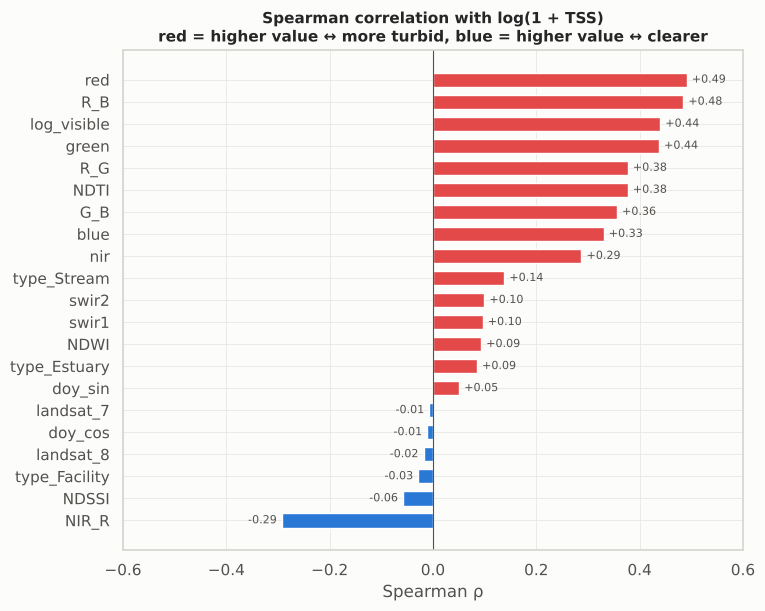

In [13]:
## Spearman correlation of every feature with log(1 + TSS) (rank-based, robust to outliers)
corr_target = X.corrwith(y, method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
colors = np.where(corr_target > 0, "#e34948", "#2a78d6")
ax.barh(corr_target.index, corr_target.values, color=colors, height=0.65)
for i, v in enumerate(corr_target.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK_2)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_xlim(-0.6, 0.6)
ax.set(title="Spearman correlation with log(1 + TSS)\nred = higher value ↔ more turbid, blue = higher value ↔ clearer",
       xlabel="Spearman ρ")
save_fig(fig, "04_feature_target_correlation")

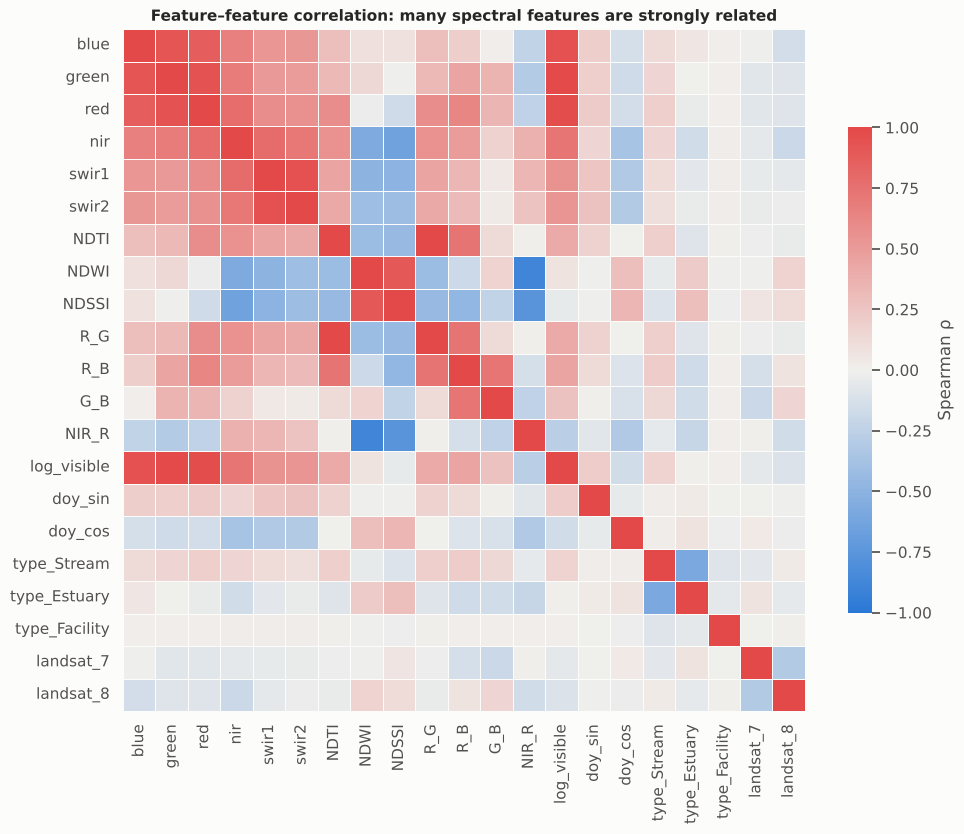

In [14]:
## correlation between features (multicollinearity check for the linear models)
corr = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=DIVERGING, norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1), square=True,
            linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Feature–feature correlation: many spectral features are strongly related")
save_fig(fig, "05_feature_correlation_heatmap")

**Observations**

- The strongest positive rank correlations with TSS are `red` (ρ = +0.49), `R_B` (+0.48), `log_visible` and `green` (+0.44),
  and `R_G` / `NDTI` (+0.38): turbid water is **brighter and redder**.
- `NIR_R` is the only clearly negative feature (ρ = −0.29): at moderate TSS the red band rises faster than the NIR band.
- `R_G` and `NDTI` have the same ρ because `NDTI = (R_G − 1) / (R_G + 1)` is an exact monotonic transform of `R_G`
  (likewise `NDWI` of G/NIR and `NDSSI` of B/NIR). Together with the strongly correlated visible bands, this creates
  **multicollinearity**: harmless for KNN, trees and SVR, but it makes linear coefficients unreliable to interpret on their own.
  Section 8 therefore relies mainly on model-agnostic permutation importance and SHAP.
- Season and sensor have almost no *direct* correlation with TSS; any value they add must come through interactions with other features.

## 5. Build Five Machine Learning Models

### 5.1 Train/test split grouped by site

`GroupShuffleSplit` puts 80 % of the **sites** in the training set and 20 % in the test set. The test set is locked away
and used **only once**, in Section 7.

In [15]:
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

shared_sites = set(g_train) & set(g_test)
print(f"Train: {len(X_train):,} rows from {g_train.nunique():,} sites")
print(f"Test : {len(X_test):,} rows from {g_test.nunique():,} sites")
print(f"Sites in both train and test: {len(shared_sites)}")
assert len(shared_sites) == 0

pd.DataFrame({
    "train (%)": df.iloc[train_idx]["type"].value_counts(normalize=True).mul(100).round(1),
    "test (%)": df.iloc[test_idx]["type"].value_counts(normalize=True).mul(100).round(1),
})

Train: 102,142 rows from 16,903 sites
Test : 26,461 rows from 4,226 sites
Sites in both train and test: 0


,train (%),test (%)
type,,
Stream,49.1,47.4
Estuary,26.7,27.9
Lake,23.5,23.6
Facility,0.8,1.1


### 5.2 Model definitions

Every model is a scikit-learn `Pipeline`, so clipping and scaling are fitted **inside** each cross-validation fold (no
leakage from the validation fold). Hyperparameters start at the **scikit-learn defaults**; Section 6 tunes them.

| # | Model | Pipeline | Why include it |
|---|---|---|---|
| 1 | Multiple Linear Regression | `QuantileClipper` → `StandardScaler` → `LinearRegression` | Baseline: is the reflectance–TSS relation linear? |
| 2 | Polynomial Ridge Regression | `QuantileClipper` → `StandardScaler` → `PolynomialFeatures(degree=2)` → `Ridge(alpha=1)` | Adds squared and interaction terms; L2 penalty controls the 252 expanded features |
| 3 | K-Nearest Neighbors | `QuantileClipper` → `StandardScaler` → `KNeighborsRegressor(k=5)` | Predicts from spectrally similar samples; scaling is essential because it uses distances |
| 4 | Decision Tree | `QuantileClipper` → `DecisionTreeRegressor()` | Learns threshold rules; no scaling needed; easy to explain |
| 5 | Support Vector Regression | `QuantileClipper` → `StandardScaler` → `SubsampledSVR(rbf, C=1, ε=0.1)` | Smooth non-linear kernel model |

**Note on SVR.** Kernel SVR needs memory and time that grow roughly with the *square* of the number of training rows, so
fitting it on ~100 k rows is not practical. The small wrapper below fits a standard `sklearn.svm.SVR` on a random
subsample of **15,000** training rows (a different subsample is not needed per fold — the subsample is drawn from whatever
data `fit` receives). It keeps the scikit-learn API, so it works with `Pipeline`, `cross_validate`, `GridSearchCV` and
`permutation_importance` like any other model.

In [16]:
class QuantileClipper(TransformerMixin, BaseEstimator):
    """Clip each continuous column to the [lower, upper] quantiles of the data it was fitted on.

    Binary (0/1) columns are passed through unchanged. Used as the first step of every pipeline, so the
    limits come from the training fold only.
    """

    def __init__(self, lower=0.001, upper=0.999):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_, self.high_ = np.quantile(X, [self.lower, self.upper], axis=0)
        binary = np.all(np.isin(X, [0.0, 1.0]), axis=0)
        self.low_[binary], self.high_[binary] = -np.inf, np.inf
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


class SubsampledSVR(RegressorMixin, BaseEstimator):
    """RBF-kernel SVR fitted on a random subsample of at most `max_samples` training rows."""

    def __init__(self, max_samples=15000, C=1.0, epsilon=0.1, gamma="scale", random_state=None):
        self.max_samples = max_samples
        self.C = C
        self.epsilon = epsilon
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        idx = rng.choice(len(X), size=min(self.max_samples, len(X)), replace=False)
        self.svr_ = SVR(kernel="rbf", C=self.C, epsilon=self.epsilon, gamma=self.gamma, cache_size=1000)
        self.svr_.fit(X[idx], y[idx])
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return self.svr_.predict(np.asarray(X))


def make_models():
    """Return fresh (unfitted) copies of the five models with default hyperparameters."""
    return {
        "Linear Regression": Pipeline([("clip", QuantileClipper()), ("scaler", StandardScaler()),
                                       ("model", LinearRegression())]),
        "Polynomial Ridge": Pipeline([("clip", QuantileClipper()), ("scaler", StandardScaler()),
                                      ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                                      ("model", Ridge(alpha=1.0))]),
        "KNN": Pipeline([("clip", QuantileClipper()), ("scaler", StandardScaler()),
                         ("model", KNeighborsRegressor(n_neighbors=5))]),
        "Decision Tree": Pipeline([("clip", QuantileClipper()),
                                   ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
        "SVR": Pipeline([("clip", QuantileClipper()), ("scaler", StandardScaler()),
                         ("model", SubsampledSVR(random_state=RANDOM_STATE))]),
    }


make_models()

{'Linear Regression': Pipeline(steps=[('clip', QuantileClipper()), ('scaler', StandardScaler()),
                 ('model', LinearRegression())]),
 'Polynomial Ridge': Pipeline(steps=[('clip', QuantileClipper()), ('scaler', StandardScaler()),
                 ('poly', PolynomialFeatures(include_bias=False)),
                 ('model', Ridge())]),
 'KNN': Pipeline(steps=[('clip', QuantileClipper()), ('scaler', StandardScaler()),
                 ('model', KNeighborsRegressor())]),
 'Decision Tree': Pipeline(steps=[('clip', QuantileClipper()),
                 ('model', DecisionTreeRegressor(random_state=42))]),
 'SVR': Pipeline(steps=[('clip', QuantileClipper()), ('scaler', StandardScaler()),
                 ('model', SubsampledSVR(random_state=42))])}

### 5.3 Baseline comparison with 5-fold `GroupKFold` cross-validation

Each model is trained on 4/5 of the training sites and scored on the remaining 1/5, five times. Train R² is also
reported to show over-fitting (a large gap between Train R² and CV R²).

In [17]:
GKF5 = GroupKFold(n_splits=5)
SCORING = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}


def run_cv(model, X_, y_, groups_):
    """5-fold GroupKFold cross-validation; returns one summary row."""
    cv = cross_validate(model, X_, y_, groups=groups_, cv=GKF5, scoring=SCORING,
                        return_train_score=True, n_jobs=N_JOBS)
    return {"Train R²": cv["train_R2"].mean(), "CV R²": cv["test_R2"].mean(), "CV R² std": cv["test_R2"].std(),
            "CV RMSE": -cv["test_RMSE"].mean(), "CV MAE": -cv["test_MAE"].mean(),
            "Fit time (s)": cv["fit_time"].mean()}


baseline_rows = {}
for name, model in make_models().items():
    t = time.time()
    baseline_rows[name] = run_cv(model, X_train, y_train, g_train)
    print(f"{name:<18} CV R² = {baseline_rows[name]['CV R²']:.3f}  ({time.time() - t:.0f} s)")

baseline_cv = pd.DataFrame(baseline_rows).T
baseline_cv.round(3)

Linear Regression  CV R² = 0.407  (3 s)


Polynomial Ridge   CV R² = 0.461  (4 s)


KNN                CV R² = 0.418  (82 s)


Decision Tree      CV R² = 0.019  (4 s)


SVR                CV R² = 0.460  (175 s)


,Train R²,CV R²,CV R² std,CV RMSE,CV MAE,Fit time (s)
Linear Regression,0.413,0.407,0.023,0.829,0.625,0.301
Polynomial Ridge,0.476,0.461,0.024,0.790,0.593,2.385
KNN,0.631,0.418,0.034,0.821,0.613,0.112
Decision Tree,0.993,0.019,0.062,1.066,0.761,1.966
SVR,0.480,0.460,0.025,0.791,0.587,13.420


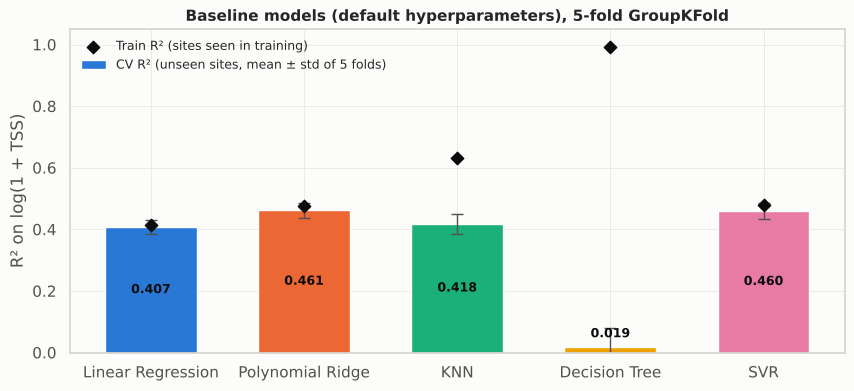

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.2))
xs = np.arange(len(MODEL_NAMES))
cv_r2 = baseline_cv.loc[MODEL_NAMES, "CV R²"].values
ax.bar(xs, np.maximum(cv_r2, 0), yerr=baseline_cv.loc[MODEL_NAMES, "CV R² std"].values * (cv_r2 > 0),
       color=[MODEL_COLORS[m] for m in MODEL_NAMES], width=0.6, capsize=4, error_kw={"elinewidth": 1, "ecolor": INK_2},
       label="CV R² (unseen sites, mean ± std of 5 folds)")
ax.scatter(xs, np.clip(baseline_cv.loc[MODEL_NAMES, "Train R²"], 0, None), marker="D", s=40, color=INK, zorder=3,
           label="Train R² (sites seen in training)")
for x_, v in zip(xs, cv_r2):
    ax.text(x_, max(v, 0) / 2 if v > 0.08 else 0.04, f"{v:.3f}", ha="center", va="center" if v > 0.08 else "bottom",
            fontsize=9, color=INK, fontweight="bold")
ax.set_xticks(xs, MODEL_NAMES)
ax.set_ylim(0, 1.05)
ax.set(title="Baseline models (default hyperparameters), 5-fold GroupKFold", ylabel="R² on log(1 + TSS)")
ax.legend(loc="upper left", frameon=False, fontsize=9)
save_fig(fig, "06_baseline_cv_comparison")

**Observations (baseline)**

- **Linear Regression** reaches CV R² = 0.407 with almost no train/CV gap (0.413 vs 0.407): it under-fits, the relationship is not linear.
- **Polynomial Ridge** (degree 2) and **SVR** are the best defaults (CV R² ≈ 0.46). Adding curvature and interactions gains ≈ +0.05.
- **KNN** with the default k = 5 over-fits (Train R² 0.631 vs CV 0.418): five neighbours are too few for noisy field data.
- The default **Decision Tree** is the textbook case of over-fitting: it memorises the training sites (Train R² 0.993) and
  is almost useless on new sites (CV R² 0.019).
- The fold-to-fold standard deviation is 0.02–0.03 (0.06 for the tree), so only differences larger than about 0.03 are meaningful.
- SVR is by far the slowest model (≈ 13 s per fit even on a 15,000-row subsample).

### 5.4 Does the feature engineering help? (RQ3)

Same cross-validation, but with only the 16 spectral/season features used on the `main` branch.

In [19]:
spectral_rows = {}
for name, model in make_models().items():
    spectral_rows[name] = run_cv(model, X_train[SPECTRAL_FEATURES], y_train, g_train)

ablation = pd.DataFrame({
    "CV R² (16 spectral features)": pd.DataFrame(spectral_rows).T["CV R²"],
    "CV R² (+ 5 context features)": baseline_cv["CV R²"],
})
ablation["Gain"] = ablation.iloc[:, 1] - ablation.iloc[:, 0]
ablation.round(3)

,CV R² (16 spectral features),CV R² (+ 5 context features),Gain
Linear Regression,0.380,0.407,0.027
Polynomial Ridge,0.420,0.461,0.042
KNN,0.360,0.418,0.058
Decision Tree,-0.046,0.019,0.065
SVR,0.416,0.460,0.044


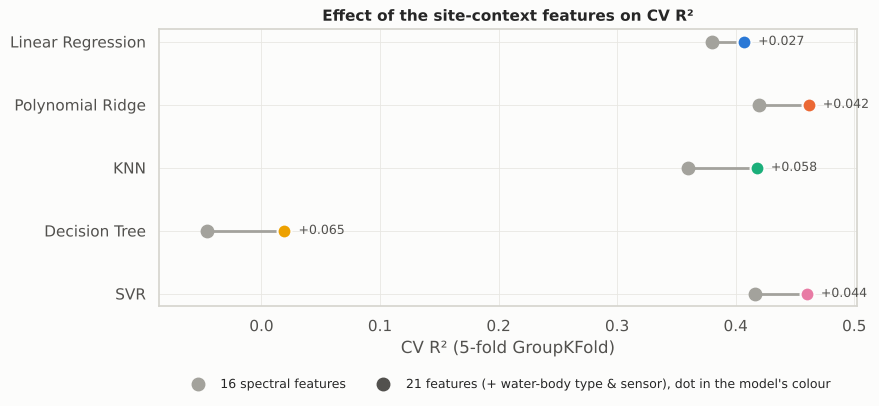

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, m in enumerate(MODEL_NAMES):
    before, after = ablation.loc[m].iloc[0], ablation.loc[m].iloc[1]
    ax.plot([before, after], [i, i], color=GRAY, linewidth=2, zorder=1)
    ax.scatter(before, i, s=80, color=GRAY, zorder=2)
    ax.scatter(after, i, s=100, color=MODEL_COLORS[m], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.text(max(before, after) + 0.012, i, f"{after - before:+.3f}", va="center", fontsize=9, color=INK_2)
ax.set_yticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.invert_yaxis()
ax.margins(x=0.08)
ax.set(title="Effect of the site-context features on CV R²", xlabel="CV R² (5-fold GroupKFold)")
ax.legend(handles=[
    plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=GRAY, label="16 spectral features"),
    plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=INK_2,
               label="21 features (+ water-body type & sensor), dot in the model's colour")],
    loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=9)
save_fig(fig, "07_feature_engineering_effect")

**Observations (feature engineering)**

- Adding the five site-context features improves **every** model, by +0.027 (Linear Regression) to +0.065 (Decision Tree) CV R².
  The flexible models gain most (KNN +0.058), because they can combine "what kind of water body" with "what colour is the water".
- Physically, water-body type carries information that one pixel cannot show: streams transport runoff and erosion sediment,
  estuaries are stirred by tides, and lakes let particles settle. The same reflectance therefore corresponds to different TSS
  in different settings.
- Both feature groups are known for any location without field sampling (from maps and image metadata), so they can be used when predicting new sites.
- **Answer to RQ3: yes.** All later sections use the 21-feature set.

## 6. Hyperparameter Tuning

`GridSearchCV` tries every combination in a small grid. Each combination is scored with **3-fold `GroupKFold`** on the
training sites only (3 folds instead of 5 to keep the run time reasonable). The test set is not touched.

| Model | Hyperparameters searched | What they control |
|---|---|---|
| Linear Regression | — | Baseline, nothing to tune |
| Polynomial Ridge | `degree` ∈ {1, 2, 3}, `alpha` ∈ {0.1, 1, 10, 100} | Model flexibility vs. L2 shrinkage |
| KNN | `n_neighbors` ∈ {5, 10, 20, 30, 50, 80}, `weights` ∈ {uniform, distance} | Smoothness of the local average |
| Decision Tree | `max_depth` ∈ {4, 6, 8, 10, 12, 15, 20, None}, `min_samples_leaf` ∈ {1, 10, 30, 100} | Tree size → over-fitting |
| SVR | `C` ∈ {1, 3, 10}, `gamma` ∈ {scale, 0.1}, `epsilon` ∈ {0.1, 0.3} | Penalty on errors, kernel width, error-free tube |

In [21]:
GKF3 = GroupKFold(n_splits=3)
PARAM_GRIDS = {
    "Polynomial Ridge": {"poly__degree": [1, 2, 3], "model__alpha": [0.1, 1, 10, 100]},
    "KNN": {"model__n_neighbors": [5, 10, 20, 30, 50, 80], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"model__max_depth": [4, 6, 8, 10, 12, 15, 20, None],
                      "model__min_samples_leaf": [1, 10, 30, 100]},
    "SVR": {"model__C": [1, 3, 10], "model__gamma": ["scale", 0.1], "model__epsilon": [0.1, 0.3]},
}

searches = {}
for name, grid in PARAM_GRIDS.items():
    t = time.time()
    search = GridSearchCV(make_models()[name], grid, cv=GKF3, scoring="r2", n_jobs=N_JOBS,
                          return_train_score=(name != "SVR"),   # SVR train predictions are slow and not plotted
                          refit=True)
    search.fit(X_train, y_train, groups=g_train)
    searches[name] = search
    best = {k.split("__")[1]: v for k, v in search.best_params_.items()}
    print(f"{name:<17} best 3-fold CV R² = {search.best_score_:.3f} | {best} | "
          f"{len(search.cv_results_['params'])} combinations in {time.time() - t:.0f} s")

Polynomial Ridge  best 3-fold CV R² = 0.460 | {'alpha': 100, 'degree': 3} | 12 combinations in 54 s


KNN               best 3-fold CV R² = 0.483 | {'n_neighbors': 30, 'weights': 'distance'} | 12 combinations in 358 s


Decision Tree     best 3-fold CV R² = 0.418 | {'max_depth': 12, 'min_samples_leaf': 100} | 32 combinations in 25 s


SVR               best 3-fold CV R² = 0.462 | {'C': 1, 'epsilon': 0.3, 'gamma': 'scale'} | 12 combinations in 390 s


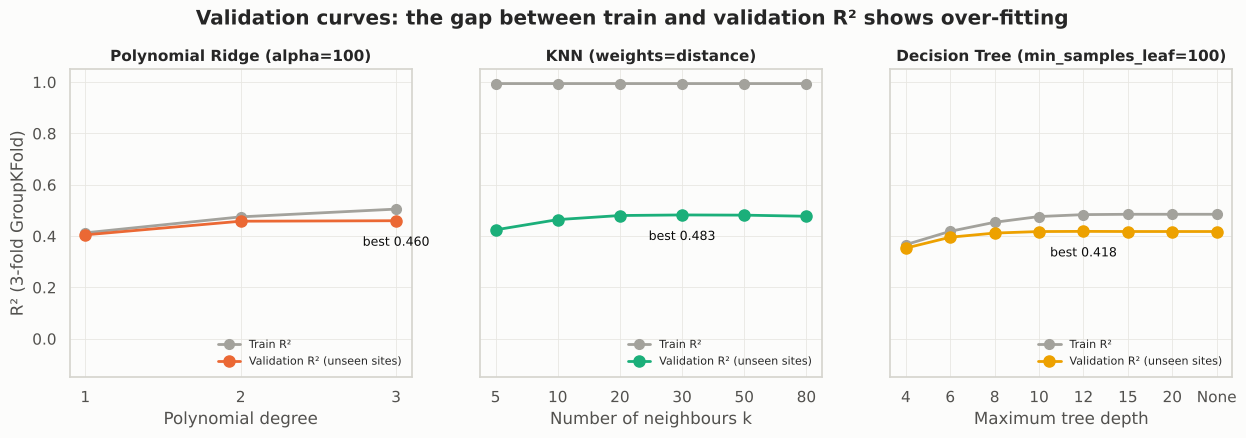

In [22]:
def curve(search, param, fixed):
    """Mean train / validation R² along one hyperparameter, with the other hyperparameters fixed at `fixed`."""
    res = search.cv_results_
    rows = [i for i, p in enumerate(res["params"]) if all(p[k] == v for k, v in fixed.items())]
    labels = [str(res["params"][i][param]) for i in rows]
    return labels, res["mean_train_score"][rows], res["mean_test_score"][rows]


bp = {name: s.best_params_ for name, s in searches.items()}
panels = [
    ("Polynomial Ridge", "poly__degree", {"model__alpha": bp["Polynomial Ridge"]["model__alpha"]}, "Polynomial degree"),
    ("KNN", "model__n_neighbors", {"model__weights": bp["KNN"]["model__weights"]}, "Number of neighbours k"),
    ("Decision Tree", "model__max_depth", {"model__min_samples_leaf": bp["Decision Tree"]["model__min_samples_leaf"]},
     "Maximum tree depth"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, param, fixed, label) in zip(axes, panels):
    xs_, tr, va = curve(searches[name], param, fixed)
    pos = np.arange(len(xs_))
    FLOOR = -0.1                                    # very negative scores are drawn at the floor and labelled
    ax.plot(pos, np.maximum(tr, FLOOR), color=GRAY, marker="o", markersize=7, linewidth=2, label="Train R²")
    ax.plot(pos, np.maximum(va, FLOOR), color=MODEL_COLORS[name], marker="o", markersize=8, linewidth=2,
            label="Validation R² (unseen sites)")
    for p_, v_ in zip(pos[va < FLOOR], va[va < FLOOR]):
        ax.annotate(f"R² = {v_:.1f}\n(off scale)", (p_, FLOOR), textcoords="offset points", xytext=(-6, 14),
                    ha="right", fontsize=8, color=INK_2)
    best_pos = int(np.argmax(va))
    ax.annotate(f"best {va[best_pos]:.3f}", (pos[best_pos], va[best_pos]), textcoords="offset points",
                xytext=(0, -18), ha="center", fontsize=9, color=INK)
    ax.set_xticks(pos, xs_)
    fixed_txt = ", ".join(f"{k.split('__')[1]}={v}" for k, v in fixed.items())
    ax.set(title=f"{name} ({fixed_txt})", xlabel=label)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_ylabel("R² (3-fold GroupKFold)")
axes[0].set_ylim(-0.15, 1.05)
fig.suptitle("Validation curves: the gap between train and validation R² shows over-fitting", fontweight="bold", y=1.03)
save_fig(fig, "08_validation_curves")

**Re-evaluate the tuned models with the same 5-fold `GroupKFold` as the baseline**, so "before" and "after" are directly comparable.

In [23]:
tuned_models = {"Linear Regression": make_models()["Linear Regression"]}
tuned_models.update({name: clone(s.best_estimator_) for name, s in searches.items()})

tuned_rows = {}
for name in MODEL_NAMES:
    t = time.time()
    tuned_rows[name] = run_cv(tuned_models[name], X_train, y_train, g_train)
    print(f"{name:<18} CV R² = {tuned_rows[name]['CV R²']:.3f}  ({time.time() - t:.0f} s)")

tuned_cv = pd.DataFrame(tuned_rows).T
tuning_compare = pd.DataFrame({
    "Train R² before": baseline_cv["Train R²"], "Train R² after": tuned_cv["Train R²"],
    "CV R² before": baseline_cv["CV R²"], "CV R² after": tuned_cv["CV R²"],
    "CV R² gain": tuned_cv["CV R²"] - baseline_cv["CV R²"],
    "CV RMSE after": tuned_cv["CV RMSE"], "CV MAE after": tuned_cv["CV MAE"],
})
best_params_table = pd.Series(
    {"Linear Regression": "—"} |
    {n: ", ".join(f"{k.split('__')[1]}={v}" for k, v in s.best_params_.items()) for n, s in searches.items()},
    name="Best hyperparameters")
tuning_compare.join(best_params_table).round(3)

Linear Regression  CV R² = 0.407  (1 s)


Polynomial Ridge   CV R² = 0.465  (40 s)


KNN                CV R² = 0.497  (80 s)


Decision Tree      CV R² = 0.425  (2 s)


SVR                CV R² = 0.461  (120 s)


,Train R² before,Train R² after,CV R² before,CV R² after,CV R² gain,CV RMSE after,CV MAE after,Best hyperparameters
Linear Regression,0.413,0.413,0.407,0.407,0.000,0.829,0.625,—
Polynomial Ridge,0.476,0.503,0.461,0.465,0.003,0.788,0.586,"alpha=100, degree=3"
KNN,0.631,0.993,0.418,0.497,0.079,0.764,0.548,"n_neighbors=30, weights=distance"
Decision Tree,0.993,0.485,0.019,0.425,0.406,0.816,0.615,"max_depth=12, min_samples_leaf=100"
SVR,0.480,0.482,0.460,0.461,0.001,0.790,0.587,"C=1, epsilon=0.3, gamma=scale"


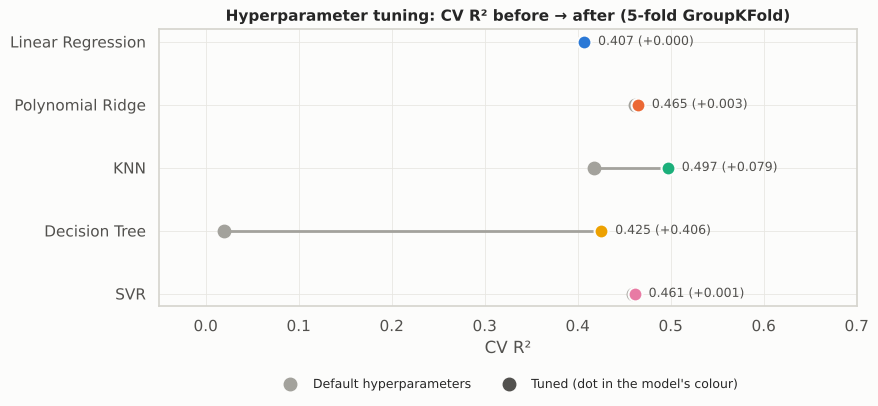

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, m in enumerate(MODEL_NAMES):
    before, after = tuning_compare.loc[m, "CV R² before"], tuning_compare.loc[m, "CV R² after"]
    before = max(before, -0.03)               # keep a collapsed baseline visible at the left edge
    ax.plot([before, after], [i, i], color=GRAY, linewidth=2, zorder=1)
    ax.scatter(before, i, s=80, color=GRAY, zorder=2)
    ax.scatter(after, i, s=100, color=MODEL_COLORS[m], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.text(max(before, after) + 0.015, i, f"{after:.3f} ({tuning_compare.loc[m, 'CV R² gain']:+.3f})", va="center", fontsize=9, color=INK_2)
ax.set_yticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.invert_yaxis()
ax.set_xlim(-0.05, 0.7)
ax.set(title="Hyperparameter tuning: CV R² before → after (5-fold GroupKFold)", xlabel="CV R²")
ax.legend(handles=[
    plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=GRAY, label="Default hyperparameters"),
    plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=INK_2, label="Tuned (dot in the model's colour)")],
    loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=9)
save_fig(fig, "09_tuning_before_after")

In [25]:
## best model = highest tuned CV R² (chosen on the training sites only, before looking at the test set)
ranking = tuned_cv.sort_values("CV R²", ascending=False)
BEST = ranking.index[0]
print("Ranking by tuned CV R²:")
for i, (name, row) in enumerate(ranking.iterrows(), 1):
    print(f"  {i}. {name:<18} {row['CV R²']:.3f} ± {row['CV R² std']:.3f}")
print(f"\nBest model (selected by cross-validation): {BEST}")

Ranking by tuned CV R²:
  1. KNN                0.497 ± 0.025
  2. Polynomial Ridge   0.465 ± 0.019
  3. SVR                0.461 ± 0.025
  4. Decision Tree      0.425 ± 0.031
  5. Linear Regression  0.407 ± 0.023

Best model (selected by cross-validation): KNN


**Observations (tuning)**

| Model | Best hyperparameters | CV R² before → after | What happened |
|---|---|---|---|
| Decision Tree | `max_depth=12`, `min_samples_leaf=100` | 0.019 → **0.425** | Large leaves stop the tree from memorising single samples; Train R² falls from 0.993 to 0.485, CV R² rises by +0.41 |
| KNN | `n_neighbors=30`, `weights=distance` | 0.418 → **0.497** | Averaging 30 neighbours smooths out field noise. (Train R² = 0.993 is not meaningful with distance weights: a training point is its own nearest neighbour.) |
| Polynomial Ridge | `degree=3`, `alpha=100` | 0.461 → 0.465 | A strong L2 penalty lets degree 3 work, but it is barely better than degree 2 |
| SVR | `C=1`, `epsilon=0.3`, `gamma=scale` | 0.460 → 0.461 | The defaults were already near the best point of this grid; the 15,000-row subsample is the more likely limit |
| Linear Regression | — | 0.407 | Nothing to tune |

- Tuning matters most for the models that over-fit by default (tree, KNN) and very little for the regularized models.
- **Best model (chosen by cross-validation, before looking at the test set): KNN**, CV R² = 0.497 ± 0.025, clearly ahead of
  Polynomial Ridge (0.465) and SVR (0.461).

## 7. Model Evaluation on Unseen Sites

All five tuned models are refitted on the **full training set** and evaluated **once** on the test set
(26 k matchups from 4 k sites the models have never seen).

Besides R², RMSE and MAE on the log scale, two easier-to-read metrics are reported:

- **Within 2× (%)** — share of predictions between half and double the measured value (|log error| ≤ log 2).
- **Typical error factor** — exp(median |log error|): "predictions are typically off by a factor of …".
- **Bias** — mean of (predicted − observed); negative = under-prediction on average.

In [26]:
final_models = {}
for name in MODEL_NAMES:
    if name in searches:
        final_models[name] = searches[name].best_estimator_      # GridSearchCV already refitted on all of X_train
    else:
        final_models[name] = tuned_models[name].fit(X_train, y_train)

test_pred = {name: m.predict(X_test) for name, m in final_models.items()}


def evaluate(y_true, y_pred):
    err = np.asarray(y_pred) - np.asarray(y_true)
    return {"Test R²": r2_score(y_true, y_pred),
            "Test RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "Test MAE": mean_absolute_error(y_true, y_pred),
            "Bias": err.mean(),
            "Within 2× (%)": 100 * np.mean(np.abs(err) <= np.log(2)),
            "Typical error factor": np.exp(np.median(np.abs(err)))}


test_results = pd.DataFrame({name: evaluate(y_test, p) for name, p in test_pred.items()}).T
test_results.insert(0, "CV R² (tuned)", tuned_cv["CV R²"])
test_results.sort_values("Test R²", ascending=False).round(3)

,CV R² (tuned),Test R²,Test RMSE,Test MAE,Bias,Within 2× (%),Typical error factor
KNN,0.497,0.529,0.778,0.547,-0.043,70.666,1.500
Polynomial Ridge,0.465,0.503,0.800,0.590,-0.043,68.433,1.572
SVR,0.461,0.496,0.805,0.591,-0.087,68.622,1.568
Decision Tree,0.425,0.469,0.826,0.616,-0.041,66.517,1.612
Linear Regression,0.407,0.447,0.844,0.628,-0.043,65.636,1.623


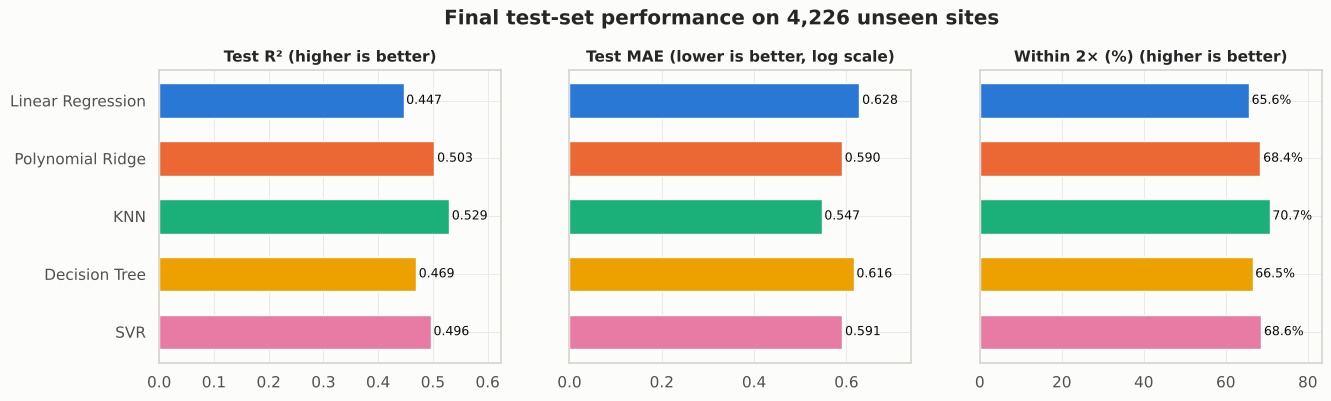

In [27]:
metrics = [("Test R²", "higher is better", "{:.3f}"), ("Test MAE", "lower is better, log scale", "{:.3f}"),
           ("Within 2× (%)", "higher is better", "{:.1f}%")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, note, fmt) in zip(axes, metrics):
    vals = test_results.loc[MODEL_NAMES, col]
    bars = ax.barh(MODEL_NAMES, vals, color=[MODEL_COLORS[m] for m in MODEL_NAMES], height=0.6)
    for bar_, v in zip(bars, vals):
        ax.text(bar_.get_width() * 1.01, bar_.get_y() + bar_.get_height() / 2, fmt.format(v),
                va="center", fontsize=9, color=INK)
    ax.set_xlim(0, vals.max() * 1.18)
    ax.set(title=f"{col} ({note})")
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("Final test-set performance on 4,226 unseen sites", fontweight="bold", y=1.04)
save_fig(fig, "10_test_metrics")

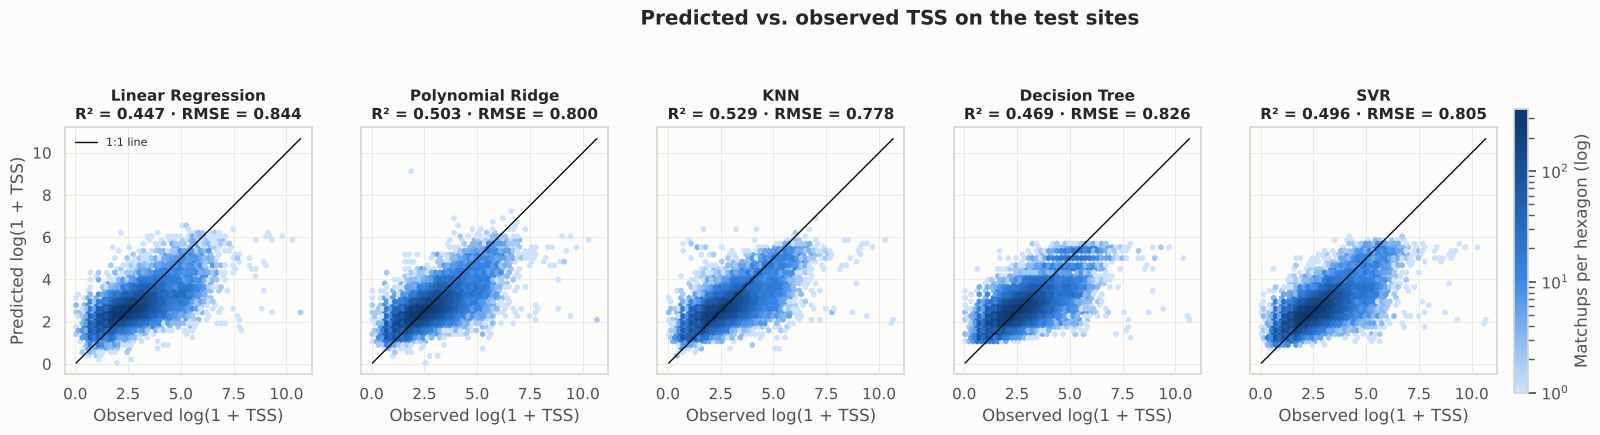

In [28]:
lims = (y_test.min(), y_test.max())
fig, axes = plt.subplots(1, 5, figsize=(22, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    hb = ax.hexbin(y_test, test_pred[name], gridsize=55, cmap=BLUES, mincnt=1, bins="log", extent=(*lims, *lims))
    ax.plot(lims, lims, color=INK, linewidth=1, label="1:1 line")
    res = test_results.loc[name]
    ax.set(title=f"{name}\nR² = {res['Test R²']:.3f} · RMSE = {res['Test RMSE']:.3f}",
           xlabel="Observed log(1 + TSS)")
    ax.set_aspect("equal")
axes[0].set_ylabel("Predicted log(1 + TSS)")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
fig.colorbar(hb, ax=axes, shrink=0.8, pad=0.01, label="Matchups per hexagon (log)")
fig.suptitle("Predicted vs. observed TSS on the test sites", fontweight="bold", y=1.02)
save_fig(fig, "11_predicted_vs_observed")

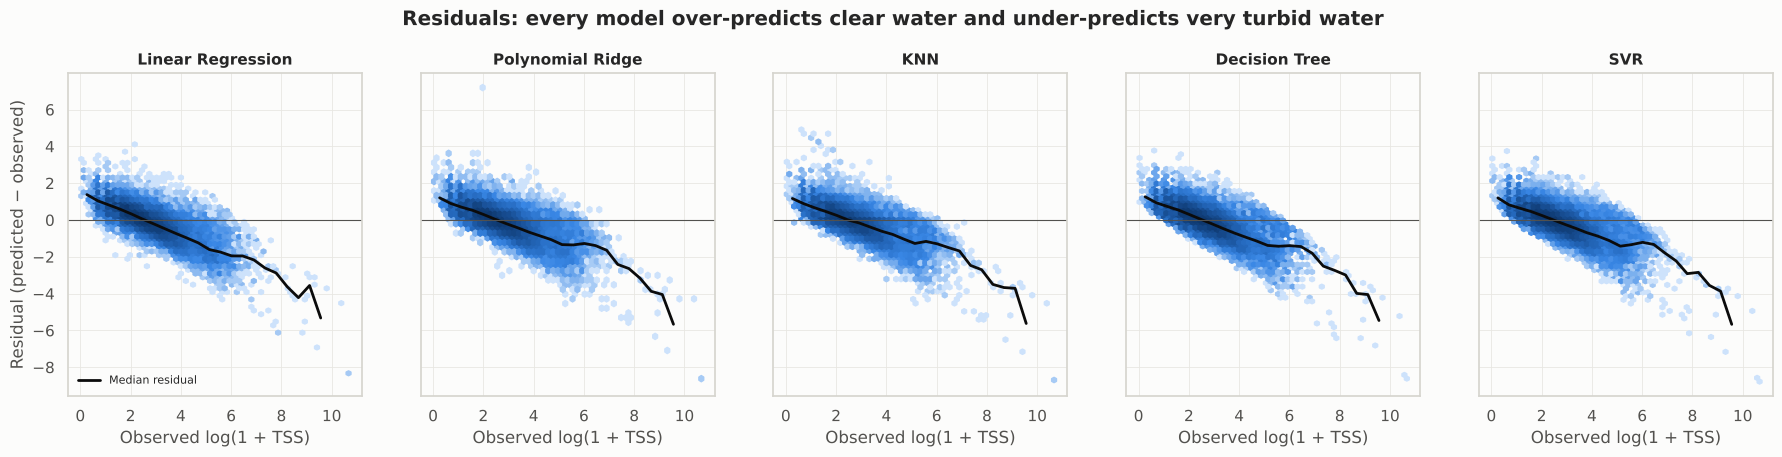

In [29]:
bins = np.linspace(lims[0], lims[1], 25)
centers = (bins[:-1] + bins[1:]) / 2
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    resid = test_pred[name] - y_test.values
    ax.hexbin(y_test, resid, gridsize=55, cmap=BLUES, mincnt=1, bins="log")
    med = (pd.Series(resid).groupby(pd.cut(y_test.values, bins, include_lowest=True), observed=False)
             .median().values)                     # one value per bin (NaN for empty bins)
    ax.plot(centers, med, color=INK, linewidth=2, label="Median residual")
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set(title=name, xlabel="Observed log(1 + TSS)")
axes[0].set_ylabel("Residual (predicted − observed)")
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
fig.suptitle("Residuals: every model over-predicts clear water and under-predicts very turbid water",
             fontweight="bold", y=1.03)
save_fig(fig, "12_residuals")

### 7.1 Where does the best model work well? (RQ5)

In [30]:
test_df = df.iloc[test_idx].assign(pred=test_pred[BEST])
by_type = (test_df.groupby("type")
                  .apply(lambda d_: pd.Series({**evaluate(d_["tss_log"], d_["pred"]),
                                               "matchups": len(d_), "sites": d_["SiteID"].nunique()}),
                         include_groups=False)
                  .loc[["Stream", "Estuary", "Lake", "Facility"]])
print(f"Best model: {BEST}")
by_type[["matchups", "sites", "Test R²", "Test MAE", "Bias", "Within 2× (%)", "Typical error factor"]].round(3)

Best model: KNN


,matchups,sites,Test R²,Test MAE,Bias,Within 2× (%),Typical error factor
type,,,,,,,
Stream,12551.0,1191.0,0.563,0.574,-0.080,69.030,1.488
Estuary,7383.0,1578.0,0.287,0.511,0.007,71.908,1.516
Lake,6246.0,1408.0,0.440,0.508,-0.024,73.951,1.486
Facility,281.0,49.0,-0.011,1.125,-0.124,38.078,2.473


### 7.2 Can the model tell clear water from turbid water?

For many management uses an exact mg/L value matters less than knowing whether a site is **clear, moderately turbid or
highly turbid**. The thresholds below are illustrative working classes for this analysis (not a regulatory standard):
**Low < 10 mg/L**, **Moderate 10–50 mg/L**, **High ≥ 50 mg/L**.

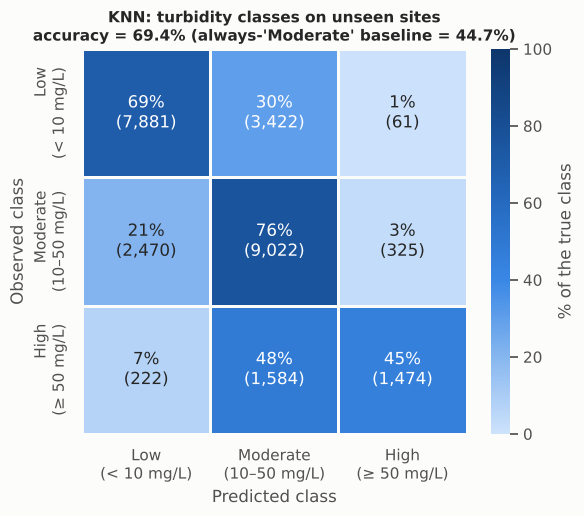

Observed class shares: {'Low': np.float64(42.9), 'Moderate': np.float64(44.7), 'High': np.float64(12.4)}
High-TSS samples (>= 50 mg/L) predicted as High: 44.9%  |  predicted as Low: 6.8%
Low-TSS samples (< 10 mg/L) predicted as Low:   69.4%  |  predicted as High: 0.5%


In [31]:
CLASS_EDGES = [0, 10, 50, np.inf]
CLASS_LABELS = ["Low\n(< 10 mg/L)", "Moderate\n(10–50 mg/L)", "High\n(≥ 50 mg/L)"]


def to_class(tss_log):
    tss_mg_l = np.clip(np.expm1(np.asarray(tss_log)), 0, None)   # back-transform; clip tiny negative predictions
    return pd.cut(tss_mg_l, CLASS_EDGES, labels=False, right=False).astype(int)


true_cls, pred_cls = to_class(y_test.values), to_class(test_pred[BEST])
cm = confusion_matrix(true_cls, pred_cls, labels=[0, 1, 2])
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
acc = accuracy_score(true_cls, pred_cls)
majority = np.bincount(true_cls).max() / len(true_cls)

fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(cm_pct, annot=np.array([[f"{p:.0f}%\n({c:,})" for p, c in zip(rp, rc)] for rp, rc in zip(cm_pct, cm)]),
            fmt="", cmap=BLUES, vmin=0, vmax=100, cbar_kws={"label": "% of the true class"},
            xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, linewidths=2, linecolor="#fcfcfb", ax=ax)
ax.set(xlabel="Predicted class", ylabel="Observed class",
       title=f"{BEST}: turbidity classes on unseen sites\naccuracy = {acc:.1%} (always-'Moderate' baseline = {majority:.1%})")
save_fig(fig, "13_turbidity_class_confusion")

print("Observed class shares:", dict(zip(["Low", "Moderate", "High"], np.round(np.bincount(true_cls) / len(true_cls) * 100, 1))))
print(f"High-TSS samples (>= 50 mg/L) predicted as High: {cm_pct[2, 2]:.1f}%  |  predicted as Low: {cm_pct[2, 0]:.1f}%")
print(f"Low-TSS samples (< 10 mg/L) predicted as Low:   {cm_pct[0, 0]:.1f}%  |  predicted as High: {cm_pct[0, 2]:.1f}%")

**Observations (evaluation)**

- **KNN is also the best model on the test set**: R² = 0.529, RMSE = 0.778, MAE = 0.547. The ranking on the test set is the
  same as in cross-validation, so the model choice is robust. Test scores are 0.03–0.04 higher than CV scores for every model,
  which means this particular test split is slightly easier, not that information leaked.
- In TSS terms the best model is typically off by a factor of **1.5** (median), and **70.7 %** of its predictions are within
  a factor of 2 of the measured value (Linear Regression: 65.6 %).
- **Regression to the mean.** All five models over-predict clear water (≈ +1 log unit for the clearest water, TSS ≈ 1 mg/L) and under-predict very
  turbid water (−2 to −5 log units above ≈ 1,000 mg/L). The shared pattern means the limit is in the information the
  features carry, not in one model type.
- **By water-body type** (KNN): best R² for **streams** (0.563), then lakes (0.440) and estuaries (0.287). Estuaries have a low R²
  but the *lowest* MAE (0.511) and 71.9 % within 2×: their TSS range is narrow (90th percentile 41 mg/L), and R² punishes a narrow range.
  **Facility** sites (281 samples, 49 sites) are poorly predicted (R² ≈ 0, 38 % within 2×), probably because they are heterogeneous
  (ponds, outfalls, reservoirs) and rare in training.
- **Turbidity classes:** 69.4 % accuracy against 44.7 % for always guessing "Moderate". The model almost never confuses the extremes:
  only 0.5 % of clear samples are called "High" and 6.8 % of highly turbid samples are called "Low". But more than half of the
  high-TSS samples (≥ 50 mg/L) are predicted as "Moderate" — the same under-prediction seen in the residuals.

## 8. Feature Importance (Explainable ML)

Three complementary views:

1. **Permutation importance** (model-agnostic, all five models): shuffle one feature in the *test* set and measure how much
   R² drops. A large drop means the model relies on that feature. Computed on a random 3,000-row sample of the test set with
   5 repeats (SVR and KNN predictions are slow).
2. **SHAP values** for the best model: how much each feature pushes an individual prediction up or down.
3. **Model-specific views**: the top of the decision tree (its first split rules) and the standardized coefficients of the linear baseline.

In [32]:
X_pi = X_test.sample(3000, random_state=RANDOM_STATE)
y_pi = y_test.loc[X_pi.index]

perm = {}
for name in MODEL_NAMES:
    t = time.time()
    pi = permutation_importance(final_models[name], X_pi, y_pi, scoring="r2", n_repeats=5,
                                random_state=RANDOM_STATE, n_jobs=N_JOBS)
    perm[name] = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=FEATURES)
    print(f"{name:<18} done ({time.time() - t:.0f} s)")

perm_mean = pd.DataFrame({n: perm[n]["mean"] for n in MODEL_NAMES})
perm_mean = perm_mean.loc[perm_mean.mean(axis=1).sort_values(ascending=False).index]
perm_mean.round(3)

Linear Regression  done (0 s)


Polynomial Ridge   done (2 s)


KNN                done (51 s)
Decision Tree      done (0 s)


SVR                done (49 s)


,Linear Regression,Polynomial Ridge,KNN,Decision Tree,SVR
R_G,1.209,1.234,0.072,0.008,0.090
red,0.190,1.535,0.065,0.346,0.088
swir1,0.235,1.455,0.043,0.059,0.183
R_B,0.172,0.832,0.078,0.296,0.063
blue,0.308,1.060,0.033,0.004,0.022
NDTI,0.401,0.819,0.060,0.045,0.061
log_visible,0.064,1.121,0.046,0.004,0.057
NDWI,0.099,1.075,0.032,0.001,0.012
nir,0.278,0.594,0.053,0.071,0.058
NIR_R,0.077,0.771,0.037,0.015,0.019


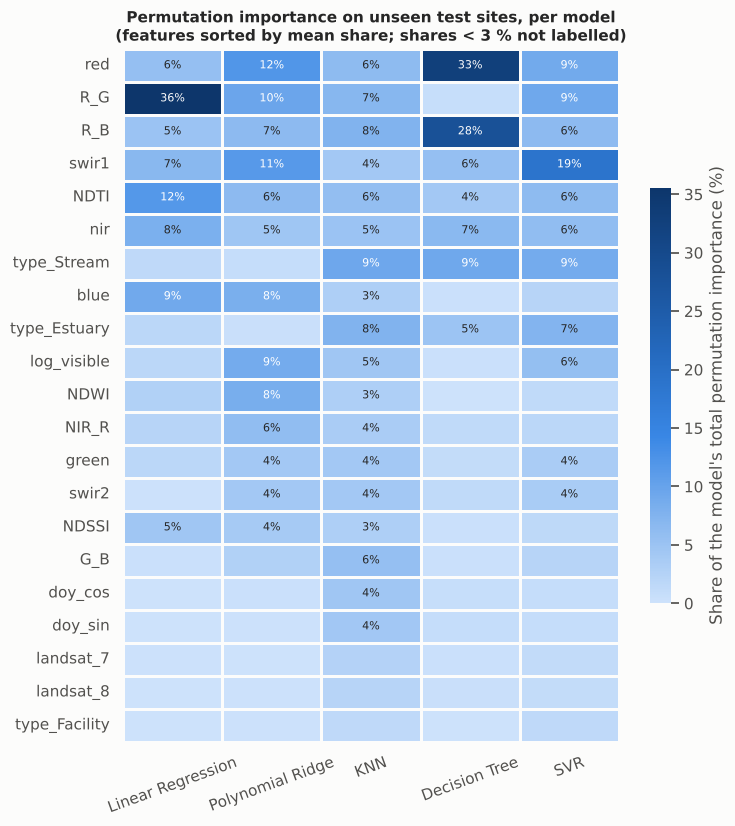

In [33]:
## models differ a lot in total importance (correlated features inflate the linear model's values),
## so each column is shown as the share of that model's total importance
perm_share = perm_mean.clip(lower=0) / perm_mean.clip(lower=0).sum() * 100
perm_share = perm_share.loc[perm_share.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 9))
annot = perm_share.map(lambda v: f"{v:.0f}%" if v >= 3 else "")
sns.heatmap(perm_share, annot=annot, fmt="", cmap=BLUES, vmin=0, linewidths=1, linecolor="#fcfcfb",
            cbar_kws={"label": "Share of the model's total permutation importance (%)", "shrink": 0.6}, ax=ax,
            annot_kws={"fontsize": 8})
ax.set(title="Permutation importance on unseen test sites, per model\n(features sorted by mean share; shares < 3 % not labelled)",
       xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
save_fig(fig, "14_permutation_importance_all_models")

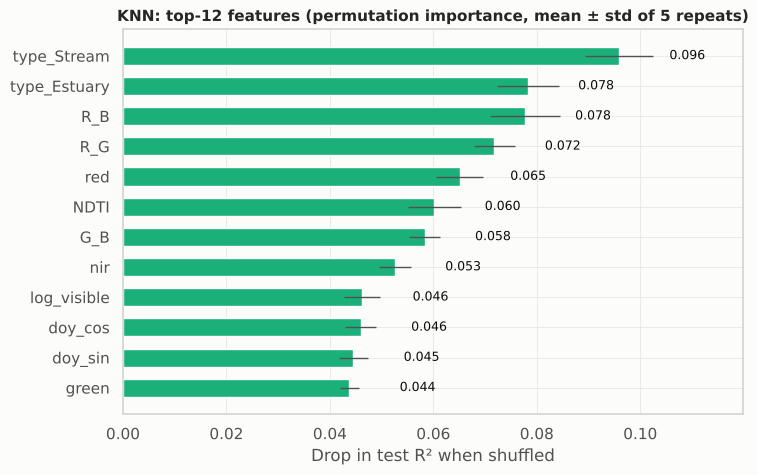

In [34]:
top = perm[BEST].sort_values("mean").tail(12)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["mean"], xerr=top["std"], color=MODEL_COLORS[BEST], height=0.6,
        error_kw={"elinewidth": 1, "ecolor": INK_2})
for i, v in enumerate(top["mean"]):
    ax.text(v + top["std"].max() + 0.003, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set(title=f"{BEST}: top-12 features (permutation importance, mean ± std of 5 repeats)",
       xlabel="Drop in test R² when shuffled")
ax.set_xlim(0, top["mean"].max() * 1.25)
save_fig(fig, "15_permutation_importance_best_model")

### 8.1 SHAP values for the best model

The best model (KNN) is not a tree, so the model-agnostic `shap.PermutationExplainer` is used with 25 background samples
from the training set and 200 explained test samples. Each explanation needs thousands of model predictions, so this is the
slowest cell of the notebook (a few minutes). Each dot is one prediction; position = effect on the predicted log(1 + TSS),
colour = the feature's value (red = high, blue = low).

SHAP values for 200 samples computed in 94 s


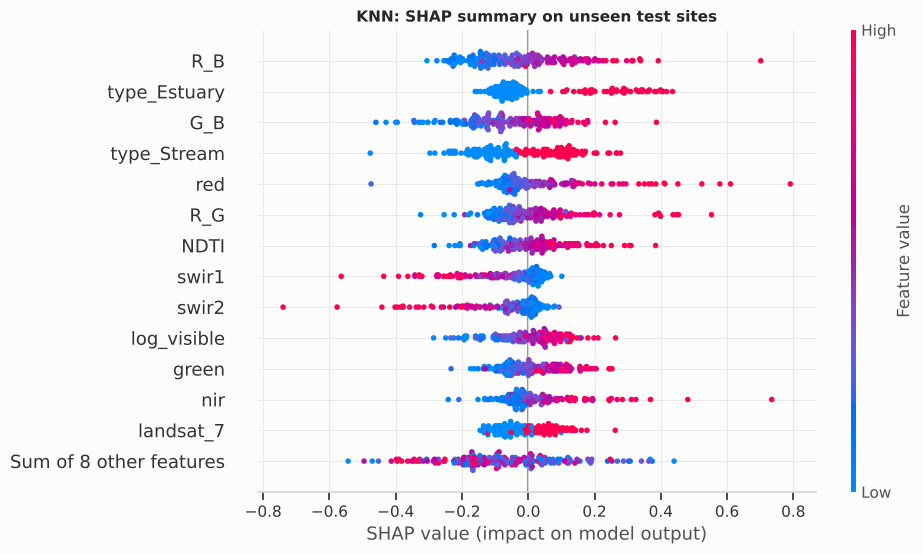

In [35]:
X_bg = X_train.sample(25, random_state=RANDOM_STATE)          # background data that "removes" a feature
X_explain = X_test.sample(200, random_state=RANDOM_STATE + 1)  # predictions to explain

t = time.time()
if BEST == "Decision Tree":
    explainer = shap.TreeExplainer(final_models[BEST].named_steps["model"])
    shap_values = explainer(X_explain)
else:
    explainer = shap.PermutationExplainer(final_models[BEST].predict, X_bg, seed=RANDOM_STATE)
    shap_values = explainer(X_explain, max_evals=4 * len(FEATURES) + 16,   # ~2 permutations per sample
                            silent=True)
print(f"SHAP values for {len(X_explain)} samples computed in {time.time() - t:.0f} s")

shap.plots.beeswarm(shap_values, max_display=14, show=False, plot_size=(9, 6))
fig = plt.gcf()
plt.title(f"{BEST}: SHAP summary on unseen test sites", fontweight="bold")
save_fig(fig, "16_shap_summary_best_model")

In [36]:
## mean |SHAP| ranking vs. permutation ranking (do both explanation methods agree?)
shap_rank = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
agree = pd.DataFrame({
    "mean |SHAP|": shap_rank.head(10).round(3),
    "permutation importance": perm[BEST]["mean"].loc[shap_rank.head(10).index].round(3),
    "permutation rank": perm[BEST]["mean"].rank(ascending=False).astype(int).loc[shap_rank.head(10).index],
})
agree

,mean |SHAP|,permutation importance,permutation rank
R_B,0.120,0.078,3
type_Estuary,0.118,0.078,2
G_B,0.114,0.058,7
type_Stream,0.111,0.096,1
red,0.096,0.065,5
R_G,0.088,0.072,4
NDTI,0.081,0.060,6
swir1,0.080,0.043,14
swir2,0.075,0.043,13
log_visible,0.075,0.046,9


### 8.2 Model-specific views: decision tree rules and linear coefficients

Tuned tree: depth = 12, leaves = 689


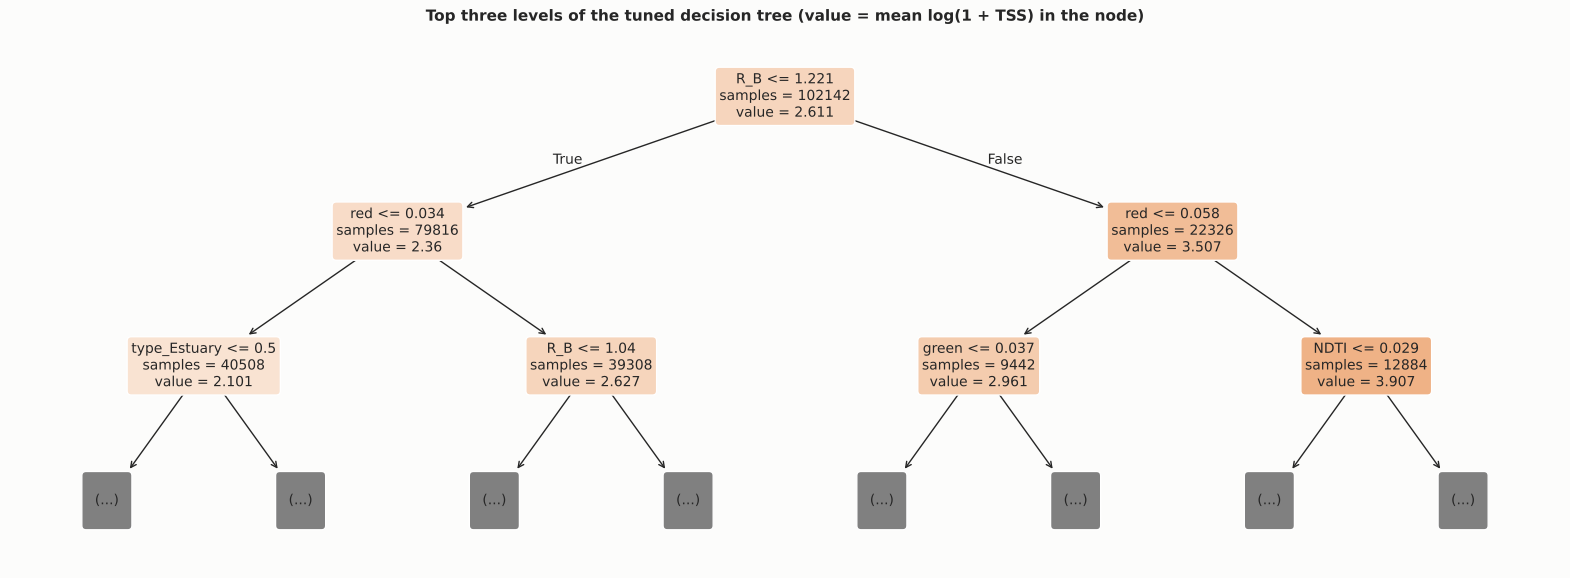

In [37]:
tree = final_models["Decision Tree"].named_steps["model"]
print(f"Tuned tree: depth = {tree.get_depth()}, leaves = {tree.get_n_leaves():,}")

fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(tree, max_depth=2, feature_names=FEATURES, filled=True, rounded=True, impurity=False,
          precision=3, fontsize=10, ax=ax)
ax.set_title("Top three levels of the tuned decision tree (value = mean log(1 + TSS) in the node)",
             fontweight="bold")
save_fig(fig, "17_decision_tree_top_levels")

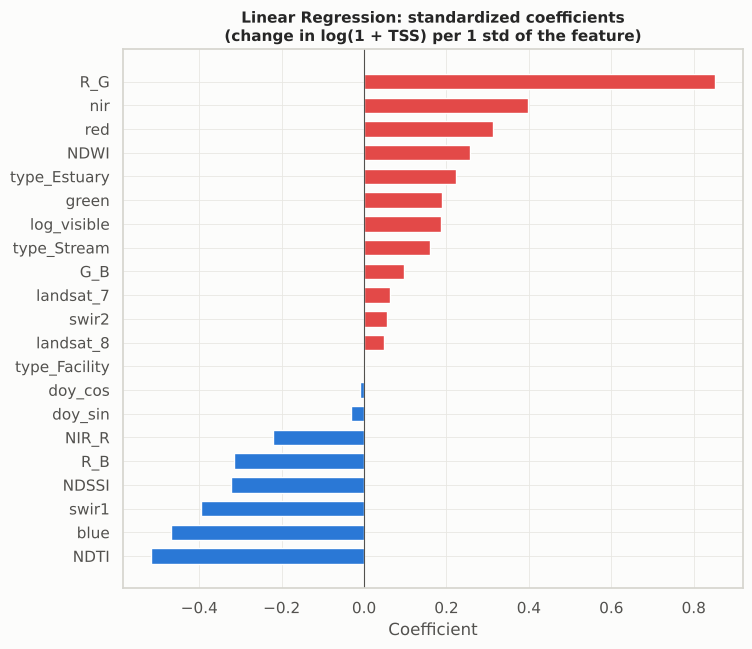

Large opposite-sign coefficients on correlated features (e.g. bands vs. log_visible) are a sign of multicollinearity, so these values should not be read as physical effects on their own.


In [38]:
lin = final_models["Linear Regression"].named_steps["model"]
coefs = pd.Series(lin.coef_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coefs.index, coefs.values, color=np.where(coefs > 0, "#e34948", "#2a78d6"), height=0.65)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set(title="Linear Regression: standardized coefficients\n(change in log(1 + TSS) per 1 std of the feature)",
       xlabel="Coefficient")
save_fig(fig, "18_linear_coefficients")
print("Large opposite-sign coefficients on correlated features (e.g. bands vs. log_visible) are a sign of "
      "multicollinearity, so these values should not be read as physical effects on their own.")

**Observations (explainability)**

- **The same physical signal drives every model.** Red-band information — `red`, `R_B`, `R_G`, `NDTI` — and `nir` are among the
  most important features for all five models. The tuned decision tree makes its first split on `R_B ≤ 1.22`
  (node means back-transform to ≈ 10 mg/L on the left vs. ≈ 32 mg/L on the right), then on `red`, `NDTI` and water-body type.
- **KNN (best model):** the top permutation features are `type_Stream` (0.096), `type_Estuary` (0.078), `R_B` (0.078),
  `R_G` (0.072), `red` (0.065) and `NDTI` (0.060). SHAP and permutation importance agree on the same top-7 set
  (R_B, R_G, G_B, red, NDTI and the two water-type flags), only the order differs.
- **Direction of effects (SHAP):** high `R_B`, `red`, `R_G`, `NDTI` and `G_B` push the prediction **up**; being a stream or an
  estuary pushes it up; high `swir1` / `swir2` push it **down**. Water absorbs almost all SWIR light, so a strong SWIR signal over
  water mostly comes from sun glint, haze or nearby land rather than from sediment. A plausible reading is that the model uses SWIR
  to discount visible brightness that is not caused by suspended particles.
- **Linear and polynomial models:** their permutation importances are inflated (> 1 for `R_G`), because the linear model gives
  near-duplicate features large opposite-sign coefficients (`R_G` ≈ +0.85, `NDTI` ≈ −0.52 per standard deviation). Shuffling one of
  them breaks the cancellation. This is why the heatmap shows each model's *share* of importance and why the coefficients should
  not be read as physical effects.
- Season (`doy_sin`, `doy_cos`) and Landsat sensor matter only a little, and mainly for KNN (≈ 4 % share each for season).

## 9. Environmental Interpretation

**What the model learned is consistent with water optics.** Clear water reflects mostly blue and green light. Suspended mineral
particles scatter light back out of the water, especially at red (and, at high concentrations, near-infrared) wavelengths, so turbid
water looks brighter and browner/redder. The features that dominate every model — the red band, the red/blue and red/green ratios
and NDTI — measure exactly this shift. The model is therefore not relying on an accidental pattern in the data.

**The setting matters as much as the colour.** Water-body type is one of the strongest predictors for the best model. Streams carry
sediment from soil erosion and runoff, estuaries are mixed by tides and waves that resuspend bottom sediment, and lakes let particles
settle. The same reflectance can also mean different things in different water: algae, dissolved organic matter (brown "tea-coloured"
water) and a visible bottom in shallow water all change the colour without adding mineral sediment.

**How accurate is "accurate enough"?** For sites the model has never seen, a typical prediction is within a factor of about 1.5 of the
measured TSS and 71 % of predictions are within a factor of 2. Clear and highly turbid waters are almost never confused with each other.
This is good enough to:

- **screen and rank** thousands of unsampled rivers, lakes and estuaries by relative turbidity;
- **target field sampling** where the satellite suggests a problem;
- reconstruct **long-term turbidity trends** from the Landsat archive (1984 onward) where no field record exists.

It is **not** good enough to replace field measurements for regulatory compliance, where an exact concentration against a threshold
is needed.

**The weakest point is the most important one.** The model strongly under-predicts the most turbid water (hundreds to thousands of
mg/L) — storm runoff, floods, dredging plumes — which are exactly the events of greatest environmental concern. Reasons: such samples
are rare in training (12 % of samples are ≥ 50 mg/L), visible reflectance saturates at very high sediment loads, and TSS changes within
hours during storms while the satellite image may be up to a day away from the field sample.

### Answers to the research questions

| | Answer |
|---|---|
| **RQ1** Can Landsat predict TSS at unseen sites? | **Moderately.** Best test R² = 0.529 on 4,226 unseen sites; typical error ≈ 1.5×; 70.7 % within 2×. Useful for relative monitoring, not for exact values. |
| **RQ2** Which model is best? Do non-linearity and tuning help? | **KNN** (k = 30, distance weights): CV R² 0.497, test R² 0.529. All non-linear models beat the linear baseline (test R² 0.447). Tuning was decisive for the Decision Tree (+0.41 CV R²) and KNN (+0.08), and negligible for Polynomial Ridge and SVR. |
| **RQ3** Does site context help? | **Yes**, for every model: +0.027 to +0.065 CV R² from water-body type and Landsat sensor. |
| **RQ4** Which features drive predictions? Physically sensible? | Red-band features (`red`, `R_B`, `R_G`, `NDTI`) and water-body type. Higher red reflectance → higher TSS, matching the optics of suspended sediment. SWIR acts as a correction (high SWIR → lower TSS). |
| **RQ5** Where does it fail? | Extreme values are compressed: clear water is over-predicted and very turbid water strongly under-predicted. Best on streams (R² 0.563), weaker on lakes (0.440) and estuaries (0.287, narrow range), poor on rare "facility" sites. |

**Comparison with the `main` branch.** The ensemble version on `main` (tuned Random Forest, 16 spectral features, no clipping)
reached test R² = 0.503 with the same cleaning and the same site-grouped 80/20 split (`random_state = 42`, so the same test sites). The best basic model here (KNN, 0.529) is slightly better, but it
also uses the new context features and outlier clipping, so the gain should be credited mainly to **feature engineering**, not to KNN
being a better algorithm than Random Forest.

### Limitations and room for improvement

1. **Add non-satellite drivers of sediment**: watershed land use, slope and soil erodibility, rainfall and streamflow in the days before
   the image, and lake depth. All models hit the same ceiling (R² ≈ 0.5), which points to missing information rather than a missing model.
2. **Tighter matchups**: keep same-day field/satellite pairs or weight samples by the time gap (`timediff`), because TSS changes quickly during storms.
3. **Stricter spatial validation**: sites on the same river or estuary are spatially correlated; grouping folds by watershed (spatial block CV)
   instead of by site would give a more conservative estimate for truly new regions.
4. **Handle the rare high-TSS events**: sample weights, a separate classifier for "high turbidity", or a loss that penalises
   under-prediction more, so that storm plumes are not flattened.
5. **Use all the data for kernel methods**: SVR was limited to 15,000 rows; a kernel approximation (e.g. `Nystroem` + linear SVR) could use
   all 100 k training rows. KNN prediction also becomes slow as the data grow.
6. **Better water-specific atmospheric correction**: the Landsat surface reflectance product is designed for land; aquatic correction
   methods reduce glint and haze errors over dark water.
7. **Ensembles and explainable boosting**: combining these models, or the Random Forest / XGBoost from `main`, with the new
   context features is the natural next step.

In [39]:
## compact summary of the final results
summary = test_results.loc[MODEL_NAMES, ["CV R² (tuned)", "Test R²", "Test RMSE", "Test MAE",
                                         "Within 2× (%)", "Typical error factor"]]
print(f"Best model: {BEST}")
summary.round(3)

Best model: KNN


,CV R² (tuned),Test R²,Test RMSE,Test MAE,Within 2× (%),Typical error factor
Linear Regression,0.407,0.447,0.844,0.628,65.636,1.623
Polynomial Ridge,0.465,0.503,0.800,0.590,68.433,1.572
KNN,0.497,0.529,0.778,0.547,70.666,1.500
Decision Tree,0.425,0.469,0.826,0.616,66.517,1.612
SVR,0.461,0.496,0.805,0.591,68.622,1.568
